In [109]:
# Auto reload
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [110]:
import json
from pathlib import Path

# Check if pipe_props.json exists and show its structure
props_path = Path("flued_module/pipe_props.json")
if not props_path.exists():
    props_path = Path("pipe_props.json")

if props_path.exists():
    with open(props_path, 'r') as f:
        props = json.load(f)
    print("Available materials:", list(props['materials'].keys()))
else:
    print(f"pipe_props.json not found at {props_path}")


Available materials: ['steel_24_gauge', 'stainless_316', 'stainless_430', 'aluminum', 'air', 'ceramic_fiber', 'mineral_wool', 'vermiculite']


In [186]:
# Cell 1: Import and setup
from flued_module.material_properties import MaterialProperties, PipeConfiguration, WallLayer, MaterialData
from flued_module.chimney import Chimney, ChimneyPart

mat_props = MaterialProperties()

# Create chimney with defaults
parts = [
    mat_props.create_single_wall_chimney_part(
        inner_diameter_ft=4/12,
        height_ft=7.5,
        material='corrugated_316_heavy',
        num_segments=3,

    ),

    mat_props.create_triple_wall_chimney_part(
        inner_diameter_ft=4/12,
        height_ft=5.0,
        z_ft=7.5,  # Only need to specify elevation
        inner_material='stainless_316',
        middle_material='ceramic_fiber',  
        outer_material='stainless_430',
        num_segments=  2,
        #T_ambient_K=273.15

    )
]

In [187]:
# Create chimney
chimney = Chimney(
      parts=parts,
      dt=1,
      total_time=1300,
      use_coupled_solver=True
  )


CHIMNEY GEOMETRY SUMMARY (Sanity Check)

Flow path from inlet to outlet:
----------------------------------------
Part 0: SINGLE vertical, L=2.29m (7.5ft), D=101.6mm (4.0in)
Part 1: TRIPLE vertical, L=1.52m (5.0ft), D=101.6mm (4.0in) (triple-wall)

----------------------------------------
Summary:
  Total parts: 2
  Total elbows: 0
  Total path length: 3.81m (12.5ft)
  Total vertical rise: 3.81m (12.5ft)
  Computational segments: 5
  Elbow loss method: K_sum
DEBUG: Initializing conditions for 2 parts
DEBUG: Part 1 (single), segments 0-2, T_ambient=20.0°C
DEBUG: Single wall initialized - T_wall[0,0] = 20.0°C
DEBUG: Part 2 (triple), segments 3-4, T_ambient=20.0°C
DEBUG: Triple wall initialized - T_liner[0,3] = 20.0°C


In [188]:
import time 
tok=time.time()
print("Running chimney simulation...")
print(f"Configuration: {len(chimney.parts)} parts, {chimney.total_segments} total segments")
print(f"Time step: {chimney.dt}s, Total time: {chimney.total_time}s")

# Run the simulation
chimney.run_simulation(save_interval=5)
tik=time.time()
print(f'Simulation took {tik-tok:.2f} seconds')

Running chimney simulation...
Configuration: 2 parts, 5 total segments
Time step: 1s, Total time: 1300s
Starting comprehensive heat transfer simulation:
  5 segments, 1300 time steps
  Time step: 1s, Total time: 1300s
    5.0% | t=  65.0s | Gas:  86.5-113.5°C | Wall:  60.9- 73.2°C
   10.0% | t= 130.0s | Gas: 157.6-188.8°C | Wall: 103.9-133.7°C
   15.0% | t= 195.0s | Gas: 213.8-249.4°C | Wall: 132.7-188.4°C
   20.0% | t= 260.0s | Gas: 257.4-298.2°C | Wall: 158.9-233.7°C
   25.0% | t= 325.0s | Gas: 293.1-337.5°C | Wall: 179.8-270.4°C
   30.0% | t= 390.0s | Gas: 323.3-369.2°C | Wall: 196.8-300.8°C
   35.0% | t= 455.0s | Gas: 347.2-394.7°C | Wall: 210.4-323.9°C
   40.0% | t= 520.0s | Gas: 366.4-415.2°C | Wall: 221.3-342.4°C
   45.0% | t= 585.0s | Gas: 381.9-431.7°C | Wall: 229.9-357.4°C
   50.0% | t= 650.0s | Gas: 394.3-445.0°C | Wall: 236.9-369.4°C
   55.0% | t= 715.0s | Gas: 404.3-455.7°C | Wall: 242.4-379.0°C
   60.0% | t= 780.0s | Gas: 412.4-464.3°C | Wall: 247.1-386.8°C
   65.0% | t= 

In [190]:

# Get summary results
summary = chimney.get_summary_data()
print("\nSimulation Results:")
print(f"Final gas temperature range: {summary['final_gas_temp_range_C'][0]:.1f} to {summary['final_gas_temp_range_C'][1]:.1f} °C")
print(f"Final wall temperature range: {summary['final_wall_temp_range_C'][0]:.1f} to {summary['final_wall_temp_range_C'][1]:.1f} °C")
print(f"Final mass flow rate: {summary['final_mass_flow_rate_kg_s']:.4f} kg/s")



Simulation Results:
Final gas temperature range: 441.0 to 493.7 °C
Final wall temperature range: 263.1 to 418.5 °C
Final mass flow rate: 0.0586 kg/s


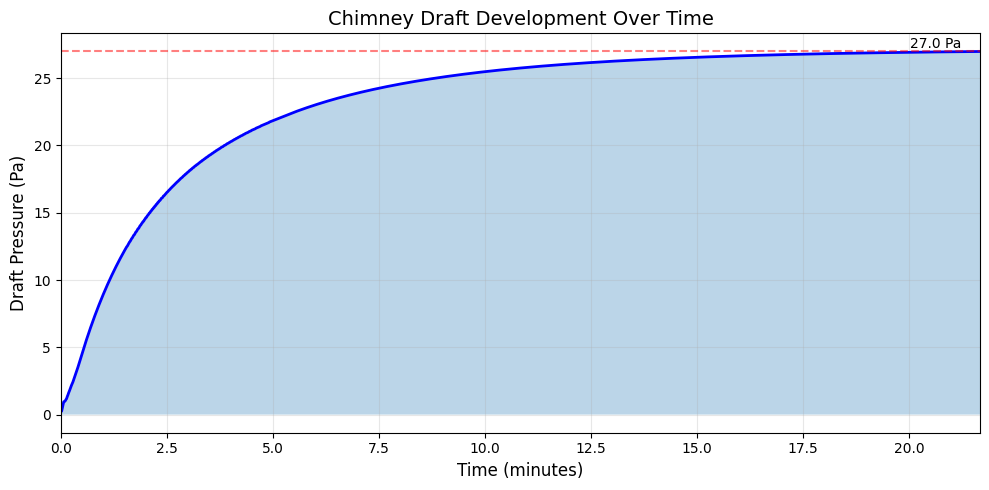

In [191]:
chimney.plot_draft_simple(name='./matrix_plots/r11_draft.png')

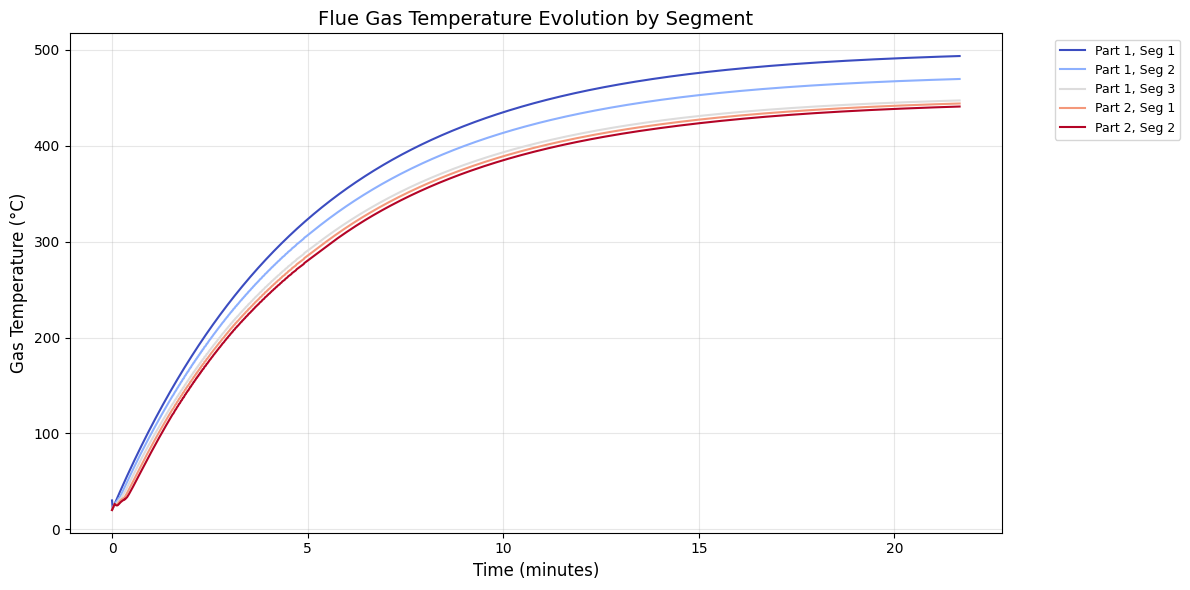

In [192]:
chimney.plot_gas_temperatures_only(name='./matrix_plots/r11_temperatures.png')


Generating temperature profile plots...


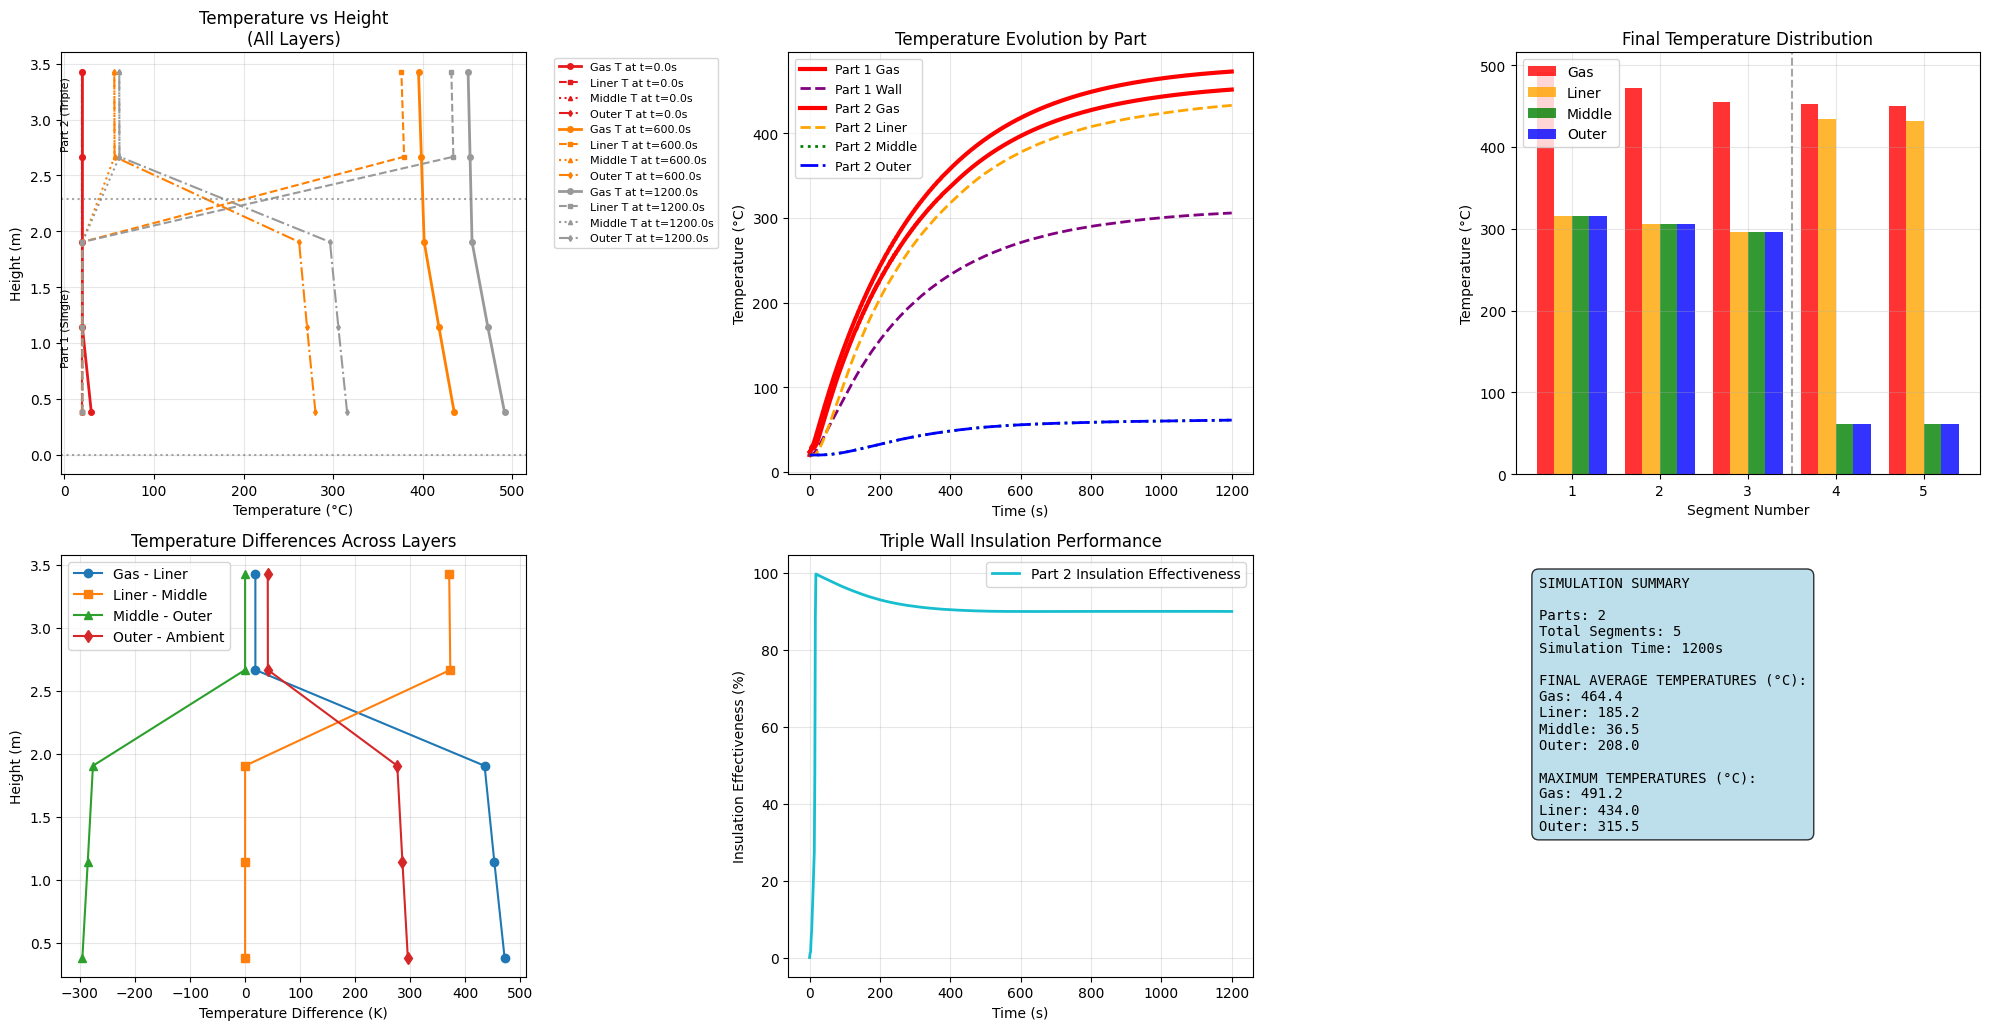


Generating segment-wise diagnostic plots...


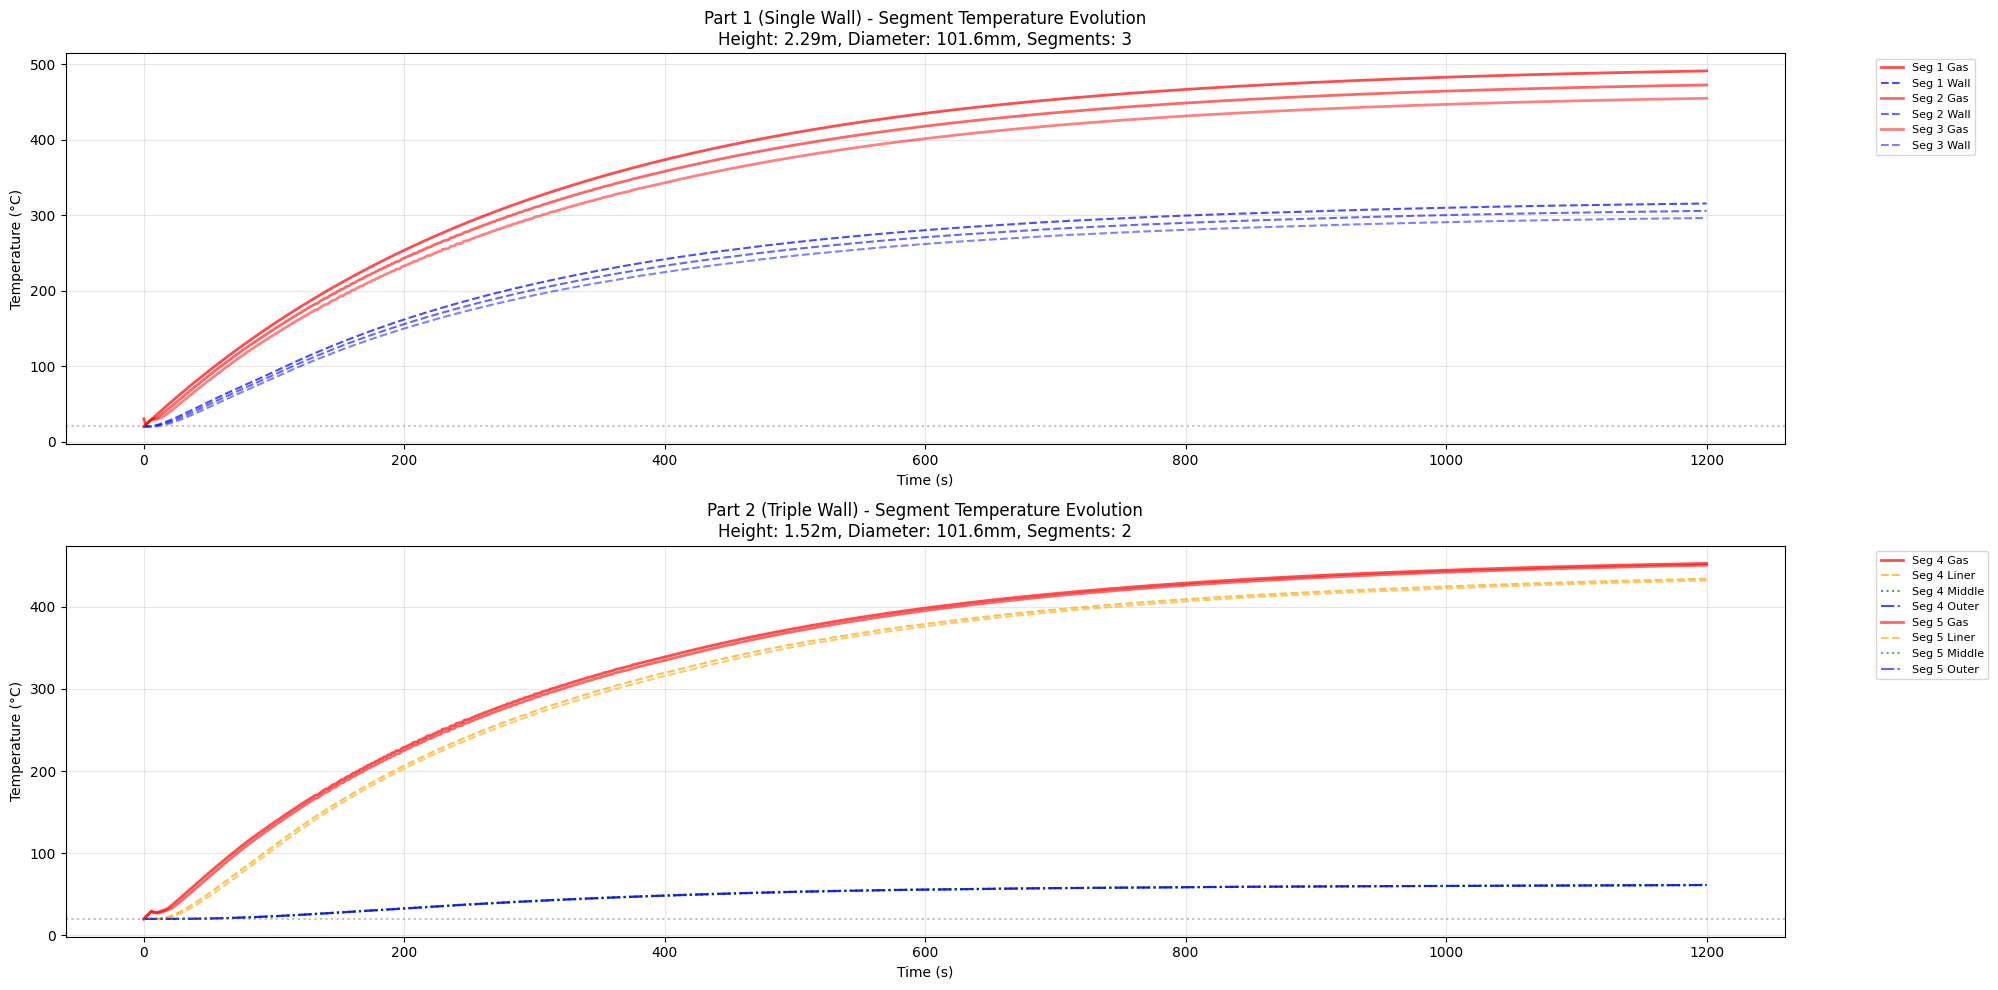

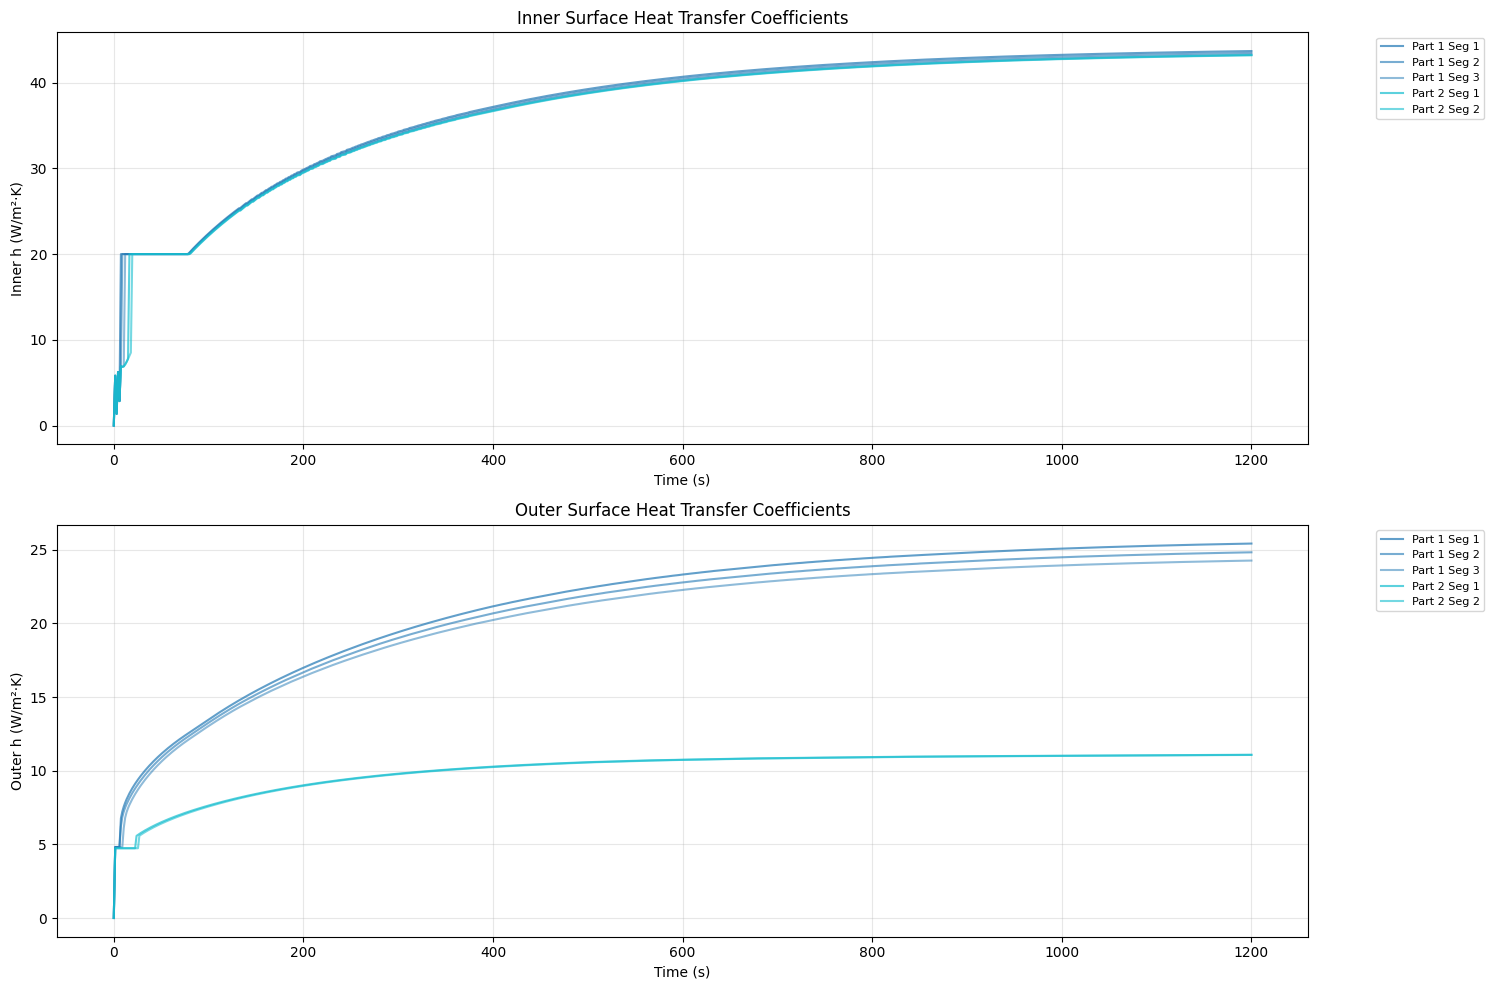


DETAILED SEGMENT INFORMATION

Part 1 (SINGLE WALL):
  Segments: 1 to 3
  Height: 2.29m
  Diameter: 101.6mm
  Final Gas Temperatures (°C): [491.20849333 472.57817988 454.90233622]
  Final Wall Temperatures (°C): [315.48493467 305.70383343 296.31914918]

Part 2 (TRIPLE WALL):
  Segments: 4 to 5
  Height: 1.52m
  Diameter: 101.6mm
  Final Gas Temperatures (°C): [452.69490158 450.48675275]
  Final Liner Temperatures (°C): [434.00858616 431.82625653]
  Final Middle Temperatures (°C): [61.36711925 61.16259098]
  Final Outer Temperatures (°C): [61.35756101 61.15308628]
  Temperature Reduction (Liner to Outer): 371.7°C
  Insulation Effectiveness: 85.9%

Simulation completed successfully!

Detailed results access:
Gas temperatures at final time (°C): [491.20849333 472.57817988 454.90233622 452.69490158 450.48675275]
Wall temperatures at final time (°C): [315.48493467 305.70383343 296.31914918 434.00858616 431.82625653]
Mass flow rates over time (kg/s): min=0.0000, max=0.0934


In [24]:

# Plot temperature profiles
print("\nGenerating temperature profile plots...")
chimney.plot_temperature_profiles()

print("\nSimulation completed successfully!")

# Example of accessing detailed data
print("\nDetailed results access:")
print(f"Gas temperatures at final time (°C): {chimney.T_gas[-1] - 273.15}")
print(f"Wall temperatures at final time (°C): {chimney.T_wall[-1] - 273.15}")
print(f"Mass flow rates over time (kg/s): min={chimney.mass_flow_rate.min():.4f}, max={chimney.mass_flow_rate.max():.4f}")

In [ ]:
import time 
tok=time.time()
print("Running chimney simulation...")
print(f"Configuration: {len(chimney.parts)} parts, {chimney.total_segments} total segments")
print(f"Time step: {chimney.dt}s, Total time: {chimney.total_time}s")

# Run the simulation
chimney.run_simulation(save_interval=5)
tik=time.time()
print(f'Simulation took {tik-tok:.2f} seconds')

 5.0% | t=  60.0s | Gas:  81.7-107.8°C | Wall:  52.6- 61.8°C
   10.0% | t= 120.0s | Gas: 148.3-178.9°C | Wall:  98.8-127.3°C
  Warning: Coupling did not converge at t=180.0s
   15.0% | t= 180.0s | Gas: 201.3-237.1°C | Wall: 136.8-182.8°C
Output is truncated. View as a scrollable element or open in a text editor. Adjust cell output settings...
c:\Users\Ana\OneDrive - LBNL\Documents\WH\flued_dynamics\flued_module\condensation_physics.py:65: RuntimeWarning: overflow encountered in scalar power
  return 10**(log10_p_kPa) * 1000  # Convert kPa to Pa
   20.0% | t= 240.0s | Gas: 243.7-284.8°C | Wall: 166.9-227.2°C
   25.0% | t= 300.0s | Gas: 277.0-323.8°C | Wall: 190.3-262.5°C
c:\Users\Ana\OneDrive - LBNL\Documents\WH\flued_dynamics\flued_module\condensation_physics.py:65: RuntimeWarning: overflow encountered in scalar multiply
  return 10**(log10_p_kPa) * 1000  # Convert kPa to Pa
   30.0% | t= 360.0s | Gas: 307.9-355.7°C | Wall: 210.2-293.1°C
   35.0% | t= 420.0s | Gas: 334.0-381.9°C | Wall: 226.3-318.2°C
   40.0% | t= 480.0s | Gas: 355.1-403.3°C | Wall: 239.4-338.3°C
   45.0% | t= 540.0s | Gas: 372.4-420.8°C | Wall: 250.0-354.7°C
   50.0% | t= 600.0s | Gas: 386.6-435.2°C | Wall: 258.6-368.1°C
   55.0% | t= 660.0s | Gas: 398.1-446.9°C | Wall: 265.7-379.2°C
   60.0% | t= 720.0s | Gas: 407.6-456.5°C | Wall: 271.4-388.2°C
   65.0% | t= 780.0s | Gas: 415.4-464.4°C | Wall: 276.2-395.5°C
   70.0% | t= 840.0s | Gas: 421.8-470.9°C | Wall: 280.4-401.6°C
   75.0% | t= 900.0s | Gas: 427.1-476.2°C | Wall: 284.0-407.1°C
   80.0% | t= 960.0s | Gas: 431.6-480.5°C | Wall: 286.9-411.8°C
   85.0% | t=1020.0s | Gas: 435.2-484.0°C | Wall: 289.3-415.8°C
   90.0% | t=1080.0s | Gas: 438.2-486.9°C | Wall: 291.2-419.0°C
   95.0% | t=1140.0s | Gas: 440.7-489.3°C | Wall: 292.8-421.7°C
  100.0% | t=1200.0s | Gas: 442.7-491.2°C | Wall: 294.1-423.9°C
Comprehensive simulation completed successfully


In [ ]:
import time 
tok=time.time()
print("Running chimney simulation...")
print(f"Configuration: {len(chimney.parts)} parts, {chimney.total_segments} total segments")
print(f"Time step: {chimney.dt}s, Total time: {chimney.total_time}s")

# Run the simulation
chimney.run_simulation(save_interval=5)
tik=time.time()
print(f'Simulation took {tik-tok:.2f} seconds')

In [ ]:

# Get summary results
summary = chimney.get_summary_data()
print("\nSimulation Results:")
print(f"Final gas temperature range: {summary['final_gas_temp_range_C'][0]:.1f} to {summary['final_gas_temp_range_C'][1]:.1f} °C")
print(f"Final wall temperature range: {summary['final_wall_temp_range_C'][0]:.1f} to {summary['final_wall_temp_range_C'][1]:.1f} °C")
print(f"Final mass flow rate: {summary['final_mass_flow_rate_kg_s']:.4f} kg/s")


In [ ]:

# Plot temperature profiles
print("\nGenerating temperature profile plots...")
chimney.plot_temperature_profiles()

print("\nSimulation completed successfully!")

# Example of accessing detailed data
print("\nDetailed results access:")
print(f"Gas temperatures at final time (°C): {chimney.T_gas[-1] - 273.15}")
print(f"Wall temperatures at final time (°C): {chimney.T_wall[-1] - 273.15}")
print(f"Mass flow rates over time (kg/s): min={chimney.mass_flow_rate.min():.4f}, max={chimney.mass_flow_rate.max():.4f}")

In [ ]:
chimney.temp_evolution_by_part(ambient_temp=False)

In [ ]:
chimney.temp_evolution_br()

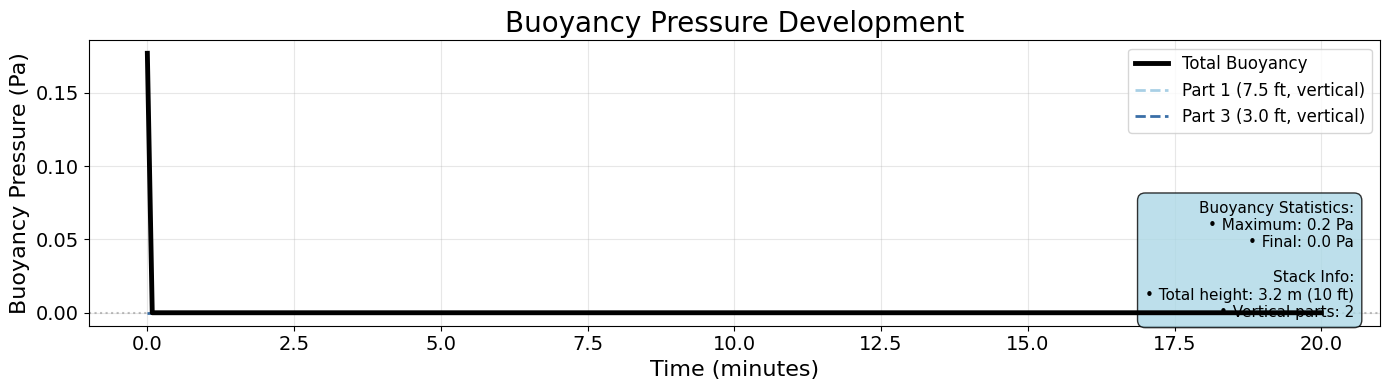

In [15]:
chimney.plot_buoyancy_pressure()

In [ ]:
chimney.temp_evolution_by_segment()

In [ ]:

# Plot temperature profiles
print("\nGenerating temperature profile plots...")
chimney.plot_temperature_profiles()

print("\nSimulation completed successfully!")

# Example of accessing detailed data
print("\nDetailed results access:")
print(f"Gas temperatures at final time (°C): {chimney.T_gas[-1] - 273.15}")
print(f"Wall temperatures at final time (°C): {chimney.T_wall[-1] - 273.15}")
print(f"Mass flow rates over time (kg/s): min={chimney.mass_flow_rate.min():.4f}, max={chimney.mass_flow_rate.max():.4f}")